In [ ]:
import os
import random
import sys

EXPERIMENT_SEED = 9
_pythonhashseed_at_kernel_start = os.environ.get("PYTHONHASHSEED")
_required_env = {
    "PYTHONHASHSEED": str(EXPERIMENT_SEED),
    "CUDA_DEVICE_ORDER": "PCI_BUS_ID",
    "CUDA_VISIBLE_DEVICES": "0",
    "CUBLAS_WORKSPACE_CONFIG": ":4096:8",
    "NVIDIA_TF32_OVERRIDE": "0",
    "OMP_NUM_THREADS": "12",
    "MKL_NUM_THREADS": "12",
}

_premature_imports = sorted(
    name for name in ("numpy", "pandas", "torch", "stable_baselines3", "finrl")
    if name in sys.modules
)
if _premature_imports:
    raise RuntimeError(
        "Restart the kernel and run this cell first; already imported: "
        + ", ".join(_premature_imports)
    )
for _name, _value in _required_env.items():
    os.environ[_name] = _value

random.seed(EXPERIMENT_SEED)
import numpy as np
import pandas as pd
import torch

np.random.seed(EXPERIMENT_SEED)
torch.manual_seed(EXPERIMENT_SEED)
torch.cuda.manual_seed_all(EXPERIMENT_SEED)
torch.set_num_threads(12)
torch.set_num_interop_threads(12)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
torch.set_float32_matmul_precision("highest")
torch.use_deterministic_algorithms(True)

if not torch.cuda.is_available():
    raise RuntimeError("1321b_ctrl requires an NVIDIA GPU, but torch.cuda.is_available() is False")
torch.cuda.set_device(0)

assert torch.are_deterministic_algorithms_enabled()
assert not torch.backends.cudnn.benchmark
assert torch.backends.cudnn.deterministic
assert not torch.backends.cuda.matmul.allow_tf32
assert not torch.backends.cudnn.allow_tf32
assert torch.get_num_threads() == 12
assert all(os.environ[name] == value for name, value in _required_env.items())

print("1321b_ctrl Phase 9 1321b_ctrl deterministic GPU bootstrap")
print("seed =", EXPERIMENT_SEED)
print("device =", torch.device("cuda:0"), torch.cuda.get_device_name(0))
print("PyTorch/CUDA =", torch.__version__, torch.version.cuda)
print("environment =", _required_env)
if _pythonhashseed_at_kernel_start != str(EXPERIMENT_SEED):
    print(
        "WARNING: PYTHONHASHSEED was not set to this seed when the Jupyter kernel "
        "started. The cell sets it for child processes, but strict interpreter-level "
        "hash reproducibility requires launching/restarting the kernel with "
        f"PYTHONHASHSEED={EXPERIMENT_SEED}."
    )


1321b_ctrl Phase 9 1321b_ctrl deterministic GPU bootstrap
seed = 9
device = cuda:0 NVIDIA GeForce RTX 2080 Ti
PyTorch/CUDA = 2.9.1+cu128 12.8
environment = {'PYTHONHASHSEED': '9', 'CUDA_DEVICE_ORDER': 'PCI_BUS_ID', 'CUDA_VISIBLE_DEVICES': '0', 'CUBLAS_WORKSPACE_CONFIG': ':4096:8', 'NVIDIA_TF32_OVERRIDE': '0', 'OMP_NUM_THREADS': '12', 'MKL_NUM_THREADS': '12'}


<a id='1'></a>
# Part 2. Getting Started- Load Python Packages


In [ ]:
import os
import sys
from pathlib import Path

PROJECT_ROOT = Path(os.environ.get("RGPPO_ROOT", str(Path.cwd())))
while not (PROJECT_ROOT / "data" / "new_version_2026").exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

os.environ["OMP_NUM_THREADS"] = "12"
os.environ["MKL_NUM_THREADS"] = "12"

print("OMP_NUM_THREADS =", os.environ["OMP_NUM_THREADS"])
print("MKL_NUM_THREADS =", os.environ["MKL_NUM_THREADS"])

import numpy as np
import pandas as pd
import torch
print("PyTorch CPU threads:", torch.get_num_threads())


OMP_NUM_THREADS = 12
MKL_NUM_THREADS = 12
PyTorch CPU threads: 12


<a id='1.1'></a>
## 2.1. Install all the packages through FinRL library


In [ ]:
%load_ext autoreload
%autoreload 2



<a id='1.2'></a>
## 2.2. Check if the additional packages needed are present, if not 


<a id='1.3'></a>
## 2.3. Import Packages


In [ ]:
import warnings
warnings.filterwarnings("ignore")


In [ ]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import datetime
from pathlib import Path

%matplotlib inline

from finrl.config import INDICATORS
from finrl.meta.preprocessor.preprocessors import FeatureEngineer
from finrl.plot import backtest_stats, backtest_plot, get_daily_return, get_baseline
from scripts.Tail_GAE.src.mda_ppo_audit import MDAAuditConfig, audit_mda_ppo_run
from scripts.Tail_GAE.src.notebook_config import (
    DATA_FILE, DJI_FILE, PPO_MODEL_KWARGS, PPO_TIMESTEPS, get_experiment_config,
)
from scripts.Tail_GAE.src.tail_gae_data import load_tail_data
from scripts.Tail_GAE.src.tail_gae_rolling_runner import TailGAERollingRunner

from pprint import pprint


<a id='1.4'></a>
## 2.4. Create Folders


In [ ]:
import os
from finrl.main import check_and_make_directories
from finrl.config import (DATA_SAVE_DIR, TRAINED_MODEL_DIR, TENSORBOARD_LOG_DIR, RESULTS_DIR, INDICATORS, 
                          TRAIN_START_DATE, TRAIN_END_DATE, TEST_START_DATE, TEST_END_DATE, TRADE_START_DATE, TRADE_END_DATE)

check_and_make_directories([DATA_SAVE_DIR, TRAINED_MODEL_DIR, TENSORBOARD_LOG_DIR, RESULTS_DIR])

<a id='2'></a>
# Part 3. Download Data
Yahoo Finance is a website that provides stock data, financial news, financial reports, etc. All the data provided by Yahoo Finance is free.
* FinRL uses a class **YahooDownloader** to fetch data from Yahoo Finance API
* Call Limit: Using the Public API (without authentication), you are limited to 2,000 requests per hour per IP (or up to a total of 48,000 requests a day).


In [7]:
TRAIN_START_DATE = '2013-04-01'
TRAIN_END_DATE = '2024-12-31'
TEST_START_DATE = '2025-01-01'
TEST_END_DATE = '2026-06-01'


DATA_FILE = PROJECT_ROOT / "data/new_version_2026/data_30_20100101_20260601.csv"
DJI_FILE = PROJECT_ROOT / "data/DJI_2013_2026.csv"

# df = YahooDownloader(start_date = TRAIN_START_DATE,
#                      end_date = TEST_END_DATE,
#                      ticker_list = DOW_30_TICKER).fetch_data()
df = pd.read_csv(DATA_FILE)
df.head()


,date,close,high,low,open,volume,tic,day
0,2010-01-04,6.406482,6.421151,6.357688,6.389120,493729600,AAPL,0
1,2010-01-04,38.748535,38.849231,37.969805,38.016797,5277400,AMGN,0
2,2010-01-04,6.695000,6.830500,6.657000,6.812500,151998000,AMZN,0
3,2010-01-04,32.380951,32.523389,31.961551,32.293908,6894300,AXP,0
4,2010-01-04,43.777561,43.941200,42.702213,43.419113,6186700,BA,0


# Part 4: Preprocess Data
Data preprocessing is a crucial step for training a high quality machine learning model. We need to check for missing data and do feature engineering in order to convert the data into a model-ready state.
* Add technical indicators. In practical trading, various information needs to be taken into account, for example the historical stock prices, current holding shares, technical indicators, etc. In this article, we demonstrate two trend-following technical indicators: MACD and RSI.
* Add turbulence index. Risk-aversion reflects whether an investor will choose to preserve the capital. It also influences one's trading strategy when facing different market volatility level. To control the risk in a worst-case scenario, such as financial crisis of 2007–2008, FinRL employs the financial turbulence index that measures extreme asset price fluctuation.


In [ ]:
fe = FeatureEngineer(use_technical_indicator=True,
                     tech_indicator_list = INDICATORS,
                     use_turbulence=True,
                     user_defined_feature = False)

processed = fe.preprocess_data(df)
processed = processed.copy()
processed = processed.fillna(0)
processed = processed.replace(np.inf,0)

Successfully added technical indicators


Successfully added turbulence index


<a id='4'></a>
# Part 5. Design Environment
Considering the stochastic and interactive nature of the automated stock trading tasks, a financial task is modeled as a **Markov Decision Process (MDP)** problem. The training process involves observing stock price change, taking an action and reward's calculation to have the agent adjusting its strategy accordingly. By interacting with the environment, the trading agent will derive a trading strategy with the maximized rewards as time proceeds.

Our trading environments, based on OpenAI Gym framework, simulate live stock markets with real market data according to the principle of time-driven simulation.

The action space describes the allowed actions that the agent interacts with the environment. Normally, action a includes three actions: {-1, 0, 1}, where -1, 0, 1 represent selling, holding, and buying one share. Also, an action can be carried upon multiple shares. We use an action space {-k,…,-1, 0, 1, …, k}, where k denotes the number of shares to buy and -k denotes the number of shares to sell. For example, "Buy 10 shares of AAPL" or "Sell 10 shares of AAPL" are 10 or -10, respectively. The continuous action space needs to be normalized to [-1, 1], since the policy is defined on a Gaussian distribution, which needs to be normalized and symmetric.


In [ ]:
# Phase 9 experiment identity (contract v3): 1321b_ctrl = 1321b_ctrl.
# 变更组合: A + D + CEF(β=0) 控制.
# 五元组 (direct_penalty_beta, recovery_penalty_beta, aux_mean_prox_clip,
#         use_phase9_observation, phase9_calendar_variant) = (0.03, 0.0, None, True, 'treatment').
EXPERIMENT_ID = "1321b_ctrl"
PHASE9_EXPERIMENT_ID = EXPERIMENT_ID
PHASE9_CONDITION = "1321b_ctrl"
PHASE9_USE_D = True
PHASE9_VARIANT = "treatment"
PHASE9_OBS_FIELDS = ["rf20_descriptor", "episode_age", "since_episode_end"]
exp_cfg = get_experiment_config(EXPERIMENT_ID, EXPERIMENT_SEED)
tail_data = load_tail_data(p_tail=float(exp_cfg["p_tail"]))

# The Phase 9 mechanisms preserve corrected-4C and the 304-dimensional policy.
processed = tail_data["processed"]
env_kwargs = dict(tail_data["env_kwargs"])
stock_dimension = int(env_kwargs["stock_dim"])
state_space = int(env_kwargs["state_space"])
risk_state_names = list(exp_cfg["risk_state_names"])
internal_risk_fields = list(exp_cfg["internal_risk_fields"])
policy_risk_fields = list(exp_cfg["policy_risk_fields"])
assert risk_state_names == []
assert len(internal_risk_fields) == 7
assert policy_risk_fields == []
# 条件映射逐位断言（contract §3.6）
assert (exp_cfg["direct_penalty_beta"], exp_cfg["recovery_penalty_beta"],
        exp_cfg["aux_mean_prox_clip"], exp_cfg["use_phase9_observation"],
        exp_cfg["phase9_calendar_variant"]) == (0.03, 0.0, None, True, 'treatment')
assert bool(exp_cfg["use_mu_ref"]) is True
assert bool(exp_cfg["direct_ref_exec_aligned"]) is True
# 策略观测维度: 301 基础 + D 模式 3 个 phase9 字段（wrapper 追加, 不归一化）
policy_state_space = state_space + (3 if PHASE9_USE_D else 0)

print(f"Phase 9 experiment: {PHASE9_EXPERIMENT_ID} / {PHASE9_CONDITION}")
print(f"Stock Dimension: {stock_dimension}")
print(f"Base State Space: {state_space}")
print(f"Internal Risk Wrapper Fields: {internal_risk_fields}")
print("Policy Risk Observation Fields: []")
print(f"Phase 9 Observation Fields: {PHASE9_OBS_FIELDS if PHASE9_USE_D else []}")
print(f"Policy Observation Dimension: {policy_state_space} (D-mode {PHASE9_USE_D})")


Successfully added technical indicators


Successfully added turbulence index


Phase 9 experiment: 1321b_ctrl / 1321b_ctrl
Stock Dimension: 30
Base State Space: 301
Internal Risk Wrapper Fields: ['current_drawdown', 'running_max_drawdown', 'drawdown_delta', 'downside_volatility_20', 'gross_exposure', 'mkt_ew_10', 'mkt_ew_5']
Policy Risk Observation Fields: []
Phase 9 Observation Fields: ['rf20_descriptor', 'episode_age', 'since_episode_end']
Policy Observation Dimension: 304 (D-mode True)


In [ ]:
# Unified Tail-GAE base-environment contract, including per-stock cost arrays.
env_kwargs = dict(tail_data["env_kwargs"])
print(env_kwargs)


{'stock_dim': 30, 'hmax': 100, 'initial_amount': 1000000, 'buy_cost_pct': [0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001], 'sell_cost_pct': [0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.001], 'tech_indicator_list': ['macd', 'boll_ub', 'boll_lb', 'rsi_30', 'cci_30', 'dx_30', 'close_30_sma', 'close_60_sma'], 'turbulence_threshold': None, 'reward_scaling': 0.0001, 'state_space': 301, 'action_space': 30}


<a id='5'></a>
# Part 6: Implement DRL Algorithms
* The implementation of the DRL algorithms are based on **OpenAI Baselines** and **Stable Baselines**. Stable Baselines is a fork of OpenAI Baselines, with a major structural refactoring, and code cleanups.
* FinRL library includes fine-tuned standard DRL algorithms, such as DQN, DDPG,
Multi-Agent DDPG, PPO, SAC, A2C and TD3. We also allow users to
design their own DRL algorithms by adapting these DRL algorithms.

* In this notebook, we are training and validating 3 agents (A2C, PPO, DDPG) using Rolling-window Ensemble Method ([reference code](https://github.com/AI4Finance-LLC/Deep-Reinforcement-Learning-for-Automated-Stock-Trading-Ensemble-Strategy-ICAIF-2020/blob/80415db8fa7b2179df6bd7e81ce4fe8dbf913806/model/models.py#L92))


In [ ]:
rebalance_window = 63
validation_window = 63
rolling_window_count = 4
print("1321b_ctrl Phase 9 1321b_ctrl rolling windows:", rolling_window_count)


1321b_ctrl Phase 9 1321b_ctrl rolling windows: 4


In [ ]:
ppo_model_kwargs = dict(PPO_MODEL_KWARGS)
ppo_model_kwargs["use_mu_ref"] = bool(exp_cfg["use_mu_ref"])
ppo_model_kwargs["grad_diag"] = True  # v4.13 P0: 训练期审计仪表（g_C/余弦/裁剪范数）
assert ppo_model_kwargs["use_mu_ref"] is True
ppo_timesteps = PPO_TIMESTEPS
print("PPO model kwargs:", ppo_model_kwargs)
print("PPO timesteps/window:", ppo_timesteps)


PPO model kwargs: {'ent_coef': 0.01, 'n_steps': 1024, 'batch_size': 256, 'learning_rate': 0.0001, 'gamma': 0.99, 'gae_lambda': 0.95, 'clip_range': 0.15, 'target_kl': 0.015, 'max_grad_norm': 0.5, 'policy_kwargs': {'net_arch': {'pi': [256, 256], 'vf': [256, 256]}}, 'use_mu_ref': True, 'grad_diag': True}
PPO timesteps/window: 40000


In [ ]:
seed = EXPERIMENT_SEED
print("seed =", seed)
print("CUBLAS_WORKSPACE_CONFIG =", os.environ["CUBLAS_WORKSPACE_CONFIG"])
print("S1 reward path = 1200 mda(lambda=0), component stats fit on window 1 then freeze")
print("S1 observation path = fit 301 dims on window 1, then freeze")
print("S1 mechanisms = internal risk wrapper √, policy risk state ×, direct loss √")


seed = 9
CUBLAS_WORKSPACE_CONFIG = :4096:8
S1 reward path = 1200 mda(lambda=0), component stats fit on window 1 then freeze
S1 observation path = fit 301 dims on window 1, then freeze
S1 mechanisms = internal risk wrapper √, policy risk state ×, direct loss √


In [ ]:
NOTEBOOK_PATH = PROJECT_ROOT / "ultimate_experiment" / "1321b Tail_GAE" / f"Tail_GAE_1321b_ctrl_seed_{seed}.ipynb"
PHASE9_OUTPUT_ROOT = Path(os.environ.get("RGPPO_RESULTS_ROOT", str(PROJECT_ROOT / "Results"))) / "Tail_GAE" / "1321b_ctrl"

phase9_calendar_path = PROJECT_ROOT / "data" / "phase9" / "gated_rf20_calendar.csv"
phase9_calendar = pd.read_csv(phase9_calendar_path, dtype={"date": str})
assert not phase9_calendar.duplicated(["window_index", "date"]).any()
assert set(phase9_calendar["window_index"]) == {0, 1, 2, 3}
phase9_calendar_sha256 = __import__("hashlib").sha256(phase9_calendar_path.read_bytes()).hexdigest()
assert phase9_calendar_sha256 == "061868855941cf013c5e976ce82c6cbd01598e5e7e8ed3995f71146047b269dc", phase9_calendar_sha256

# §1.3: runner 按当前 rolling window 取表（禁止压平）; 1324 五元组第 5 位 =
# dose_control → loss 权重读置换列, obs 表恒读 treatment 列（§2.1/§3.6）.
_suffix = "_treatment" if PHASE9_VARIANT == "treatment" else "_dose_control"
phase9_by_window = {
    int(window): {
        row["date"]: {
            "w_down": float(row["w_down" + _suffix]),
            "w_up": float(row["w_up" + _suffix]),
            "up_days_remaining": float(row["up_days_remaining" + _suffix]),
            "episode_age": float(row["episode_age" + _suffix]),
            "since_episode_end": float(row["since_episode_end" + _suffix]),
        }
        for _, row in part.iterrows()
    }
    for window, part in phase9_calendar.groupby("window_index")
}
assert set(phase9_by_window) == {0, 1, 2, 3}
# 兼容表: trajectory 模式查表承载 w_down（§3.4: supervision_weight == w_down）.
phase9_supervision_by_window = {
    window: {date: row["w_down"] for date, row in table.items()}
    for window, table in phase9_by_window.items()
}
# §2.1 D-observation: 逐 window 的 treatment 真实状态机表（与 loss 表同日期
# 域; wrapper 在 step 后装配 obs_{t+1} 时查该表, t+1 观测字段与决策日监督
# 量严格区分——§1.4）.
phase9_observation_by_window = None
if PHASE9_USE_D:
    phase9_observation_by_window = {
        int(window): {
            row["date"]: {
                "rf20_descriptor": float(row["rf20_descriptor"]),
                "episode_age": float(row["episode_age_treatment"]),
                "since_episode_end": float(row["since_episode_end_treatment"]),
            }
            for _, row in part.iterrows()
        }
        for window, part in phase9_calendar.groupby("window_index")
    }
    assert set(phase9_observation_by_window) == {0, 1, 2, 3}
    for _w in phase9_observation_by_window:
        assert set(phase9_observation_by_window[_w]) == set(phase9_by_window[_w])
        for _d, _row in phase9_observation_by_window[_w].items():
            assert 0.0 <= _row["rf20_descriptor"] <= 1.0
            assert _row["episode_age"] >= 0.0 and _row["since_episode_end"] >= 0.0

phase9_runner_kwargs = {
    "tail_alpha": 0.0,
    "i_by_date": tail_data["i_by_date"],
    "risk_state_names": [],
    "internal_risk_fields": internal_risk_fields,
    "policy_risk_fields": policy_risk_fields,
    "signal_table": tail_data["signal_table"],
    "worst20_by_date": tail_data["worst20_by_date"],
    "ew_by_date": tail_data["ew_by_date"],
    "ge_penalty_beta": 0.0,
    "ge_penalty_ref": 0.85,
    "ge_penalty_mode": "total",
    "tilt_shift": False,
    "expected_risk_observation_fields": policy_risk_fields,
    "direct_penalty_beta": float(exp_cfg["direct_penalty_beta"]),
    "direct_penalty_ref": float(exp_cfg["direct_penalty_ref"]),
    "compute_direct_diagnostics": True,
    "direct_ref_exec_aligned": bool(exp_cfg["direct_ref_exec_aligned"]),
    "trade_log": True,
}
phase9_runner_kwargs.update(
    supervision_mode="trajectory",
    supervision_weight_by_window=phase9_supervision_by_window,
    phase9_by_window=phase9_by_window,
    # Phase 9 §3.2/§3.3（B/C）: β_up 与 actor-mean 近端带; §2.1（D）观测表
    recovery_penalty_beta=float(exp_cfg["recovery_penalty_beta"]),
    aux_mean_prox_clip=exp_cfg["aux_mean_prox_clip"],
    use_phase9_observation=bool(exp_cfg["use_phase9_observation"]),
    # 1321b CEF（spec §3.3/§3.6）: 上行侧教学项剂量 β_s 与冻结参数; β_s=0
    # （控制条件/全部既有实验默认值）时该分支不进入 aux_on, 行为逐位不变.
    cef_penalty_beta=float(exp_cfg["cef_penalty_beta"]),
    cef_floor_G=float(exp_cfg["cef_floor_G"]),
    cef_band_delta=float(exp_cfg["cef_band_delta"]),
    cef_min_capacity=float(exp_cfg["cef_min_capacity"]),
    # §4.3 Stage-0 诊断：每 iter 末保存策略/价值快照（1321b 三条件开）
    save_policy_snapshot=bool(exp_cfg.get("save_policy_snapshot", False)),
)
if phase9_observation_by_window is not None:
    phase9_runner_kwargs["phase9_observation_by_window"] = phase9_observation_by_window


mda_audit_config = MDAAuditConfig(
    seed=seed,
    lambda_value=0.0,
    reward_mode="mda",
    use_risk_observation=False,
    output_root=PHASE9_OUTPUT_ROOT,
    data_path=DATA_FILE,
    notebook_path=NOTEBOOK_PATH,
    dji_path=DJI_FILE,
    deterministic=True,
    log_freq=1024,
    artifact_id=f"1321b_ctrl 1321b_ctrl",
    experiment_name=f"phase9_1321b_ctrl",
    run_directory_layout="seed_timestamp",
    normalization_config={
        "enabled": True,
        "normalize_observations": True,
        "normalize_rewards": False,
        "fit_once_on_meta_train": True,
        "normalize_mda_components": True,
        "fit_mda_components_once_on_meta_train": True,
    },
    risk_observation_fields=policy_risk_fields,
    max_windows=rolling_window_count,
    allow_ineligible_backtest=True,
    extra={
        "phase": "Phase 9 Event-Symmetric Pilot",
        "phase9_experiment_id": PHASE9_EXPERIMENT_ID,
        "phase9_condition": PHASE9_CONDITION,
        "phase9_calendar_variant": PHASE9_VARIANT,
        "phase9_calendar_sha256": phase9_calendar_sha256,
        "configuration_lineage": "corrected_4c",
        "reward_protocol": "1200_mda_lambda0_return_component_first_window_frozen",
        "observation_protocol": "1200_first_window_base_stats_frozen",
        "strict_kernel_bootstrap": True,
        "required_cublas_workspace_config": ":4096:8",
        "internal_risk_fields": internal_risk_fields,
        "policy_risk_fields": policy_risk_fields,
        "direct_penalty_beta": float(exp_cfg["direct_penalty_beta"]),
        "direct_penalty_ref": float(exp_cfg["direct_penalty_ref"]),
        "compute_direct_diagnostics": True,
        "use_mu_ref": bool(exp_cfg["use_mu_ref"]),
        "direct_ref_exec_aligned": bool(exp_cfg["direct_ref_exec_aligned"]),
        "recovery_penalty_beta": float(exp_cfg["recovery_penalty_beta"]),
        "aux_mean_prox_clip": exp_cfg["aux_mean_prox_clip"],
        "use_phase9_observation": bool(exp_cfg["use_phase9_observation"]),
        "cef_penalty_beta": float(exp_cfg["cef_penalty_beta"]),
        "cef_floor_G": float(exp_cfg["cef_floor_G"]),
        "cef_band_delta": float(exp_cfg["cef_band_delta"]),
        "cef_min_capacity": float(exp_cfg["cef_min_capacity"]),
    "save_policy_snapshot": bool(exp_cfg.get("save_policy_snapshot", False)),
        "phase9_observation_fields": PHASE9_OBS_FIELDS if PHASE9_USE_D else [],
        "timing_fix": "transition_date_frozen_pre_step (contract §1.4)",
    },
    phase9_observation_fields=PHASE9_OBS_FIELDS if PHASE9_USE_D else None,
)

mda_audit_result = audit_mda_ppo_run(
    config=mda_audit_config,
    processed=processed,
    raw_data=df,
    env_kwargs=env_kwargs,
    train_period=(exp_cfg["train_start"], exp_cfg["train_end"]),
    val_test_period=(exp_cfg["val_test_start"], exp_cfg["val_test_end"]),
    rebalance_window=rebalance_window,
    validation_window=validation_window,
    ppo_model_kwargs=ppo_model_kwargs,
    ppo_timesteps=ppo_timesteps,
    runner_cls=TailGAERollingRunner,
    runner_kwargs=phase9_runner_kwargs,
)

observation_contract = dict(mda_audit_result.runner_result["observation"])
assert observation_contract["use_risk_observation"] is False
assert observation_contract["base_observation_dim"] == state_space
assert observation_contract["risk_observation_dim"] == 0
assert observation_contract["risk_observation_fields"] == []
assert observation_contract["phase9_observation_dim"] == (3 if PHASE9_USE_D else 0)
assert observation_contract["phase9_observation_fields"] == (PHASE9_OBS_FIELDS if PHASE9_USE_D else [])
assert observation_contract["policy_observation_dim"] == policy_state_space == 304

print("Actual observation contract:")
pprint(observation_contract)
df_summary = mda_audit_result.df_summary
print("audit run_dir:", mda_audit_result.run_dir)
display(df_summary)


============Start Single PPO Strategy============
run_id: rolling
experiment_name: phase9_1321b_ctrl
reward_mode: mda
ppo_timesteps: 40000
seed(s): [9]
risk_wrapper: enabled=True, internal_dim=7, internal_fields=['current_drawdown', 'running_max_drawdown', 'drawdown_delta', 'downside_volatility_20', 'gross_exposure', 'mkt_ew_10', 'mkt_ew_5']
policy_risk_observation: enabled=False, dim=0, fields=[]
window_index: 0
iteration: 126
window_label: iter_126
seed: 9
======PPO Training========
======Model training for window: iter_126 (2013-04-01 -> 2025-01-02)
{'ent_coef': 0.01, 'n_steps': 1024, 'batch_size': 256, 'learning_rate': 0.0001, 'gamma': 0.99, 'gae_lambda': 0.95, 'clip_range': 0.15, 'target_kl': 0.015, 'max_grad_norm': 0.5, 'use_mu_ref': True, 'grad_diag': True}
Using cuda device


Logging to <results_root>/Tail_GAE/1321b_ctrl/seed_9/20261018_211323/scripts/MDA_PPO/runs/tensorboard/ppo_rolling_iter_126_seed_9_1


-----------------------------
| time/              |      |
|    fps             | 240  |
|    iterations      | 1    |
|    time_elapsed    | 4    |
|    total_timesteps | 1024 |
-----------------------------


---------------------------------------------
| time/                      |              |
|    fps                     | 209          |
|    iterations              | 2            |
|    time_elapsed            | 9            |
|    total_timesteps         | 2048         |
| train/                     |              |
|    approx_kl               | 0.0156018995 |
|    clip_fraction           | 0.267        |
|    clip_range              | 0.15         |
|    direct_gradient_norm    | 0.796        |
|    direct_loss             | 7.76         |
|    down_active_samples     | 3            |
|    down_grad_cos_ppo       | 0.0437       |
|    down_grad_norm          | 0.796        |
|    down_hinge_active       | 0.95         |
|    down_loss               | 7.76         |
|    entropy_loss            | -42.6        |
|    explained_variance      | -0.0309      |
|    grad_cos_pc             | 0.0437       |
|    grad_logstd_ent         | 0.0548       |
|    grad_logstd_pg          | 0.4

Early stopping at step 8 due to reaching max kl: 0.03


...

======PPO Validation from: 2025-10-06 to 2026-01-06


hit end!
Validation account_value path: <results_root>/Tail_GAE/1321b_ctrl/seed_9/20261018_211323/scripts/MDA_PPO/runs/rolling/phase9_1321b_ctrl/account_value_validation_phase9_1321b_ctrl_iter_315.csv
======Trading from: 2026-01-05 to 2026-04-08
Used Model: PPO


Trade account_value path: <results_root>/Tail_GAE/1321b_ctrl/seed_9/20261018_211323/scripts/MDA_PPO/runs/rolling/phase9_1321b_ctrl/account_value_trade_phase9_1321b_ctrl_iter_315.csv
Runner summary path: <results_root>/Tail_GAE/1321b_ctrl/seed_9/20261018_211323/scripts/MDA_PPO/runs/rolling/phase9_1321b_ctrl/runner_summary.csv
Single PPO Strategy took: 4 window(s)


Actual observation contract:
{'base_observation_dim': 301,
 'phase9_observation_dim': 3,
 'phase9_observation_fields': ['rf20_descriptor',
                               'episode_age',
                               'since_episode_end'],
 'policy_observation_dim': 304,
 'risk_observation_dim': 0,
 'risk_observation_fields': [],
 'use_risk_observation': False}
audit run_dir: <results_root>/Tail_GAE/1321b_ctrl/seed_9/20261018_211323


,run_id,experiment_name,reward_mode,lambda_value,seed,window_index,iteration,window_label,model_name,ppo_timesteps,validation_account_value_path,trade_account_value_path,quality_gate_status,quality_gate_reason,use_risk_observation,base_observation_dim,risk_observation_dim,risk_observation_fields,policy_observation_dim
0,rolling,phase9_1321b_ctrl,mda,0.0,9,0,126,iter_126,ppo,40000,/Tail_GAE/1321b_ctr...,/Tail_GAE/1321b_ctr...,disabled,quality gate disabled,False,301,0,[],304
1,rolling,phase9_1321b_ctrl,mda,0.0,9,1,189,iter_189,ppo,40000,/Tail_GAE/1321b_ctr...,/Tail_GAE/1321b_ctr...,disabled,quality gate disabled,False,301,0,[],304
2,rolling,phase9_1321b_ctrl,mda,0.0,9,2,252,iter_252,ppo,40000,/Tail_GAE/1321b_ctr...,/Tail_GAE/1321b_ctr...,disabled,quality gate disabled,False,301,0,[],304
3,rolling,phase9_1321b_ctrl,mda,0.0,9,3,315,iter_315,ppo,40000,/Tail_GAE/1321b_ctr...,/Tail_GAE/1321b_ctr...,disabled,quality gate disabled,False,301,0,[],304


In [15]:
df_summary


,run_id,experiment_name,reward_mode,lambda_value,seed,window_index,iteration,window_label,model_name,ppo_timesteps,validation_account_value_path,trade_account_value_path,quality_gate_status,quality_gate_reason,use_risk_observation,base_observation_dim,risk_observation_dim,risk_observation_fields,policy_observation_dim
0,rolling,phase9_1321b_ctrl,mda,0.0,9,0,126,iter_126,ppo,40000,/Tail_GAE/1321b_ctr...,/Tail_GAE/1321b_ctr...,disabled,quality gate disabled,False,301,0,[],304
1,rolling,phase9_1321b_ctrl,mda,0.0,9,1,189,iter_189,ppo,40000,/Tail_GAE/1321b_ctr...,/Tail_GAE/1321b_ctr...,disabled,quality gate disabled,False,301,0,[],304
2,rolling,phase9_1321b_ctrl,mda,0.0,9,2,252,iter_252,ppo,40000,/Tail_GAE/1321b_ctr...,/Tail_GAE/1321b_ctr...,disabled,quality gate disabled,False,301,0,[],304
3,rolling,phase9_1321b_ctrl,mda,0.0,9,3,315,iter_315,ppo,40000,/Tail_GAE/1321b_ctr...,/Tail_GAE/1321b_ctr...,disabled,quality gate disabled,False,301,0,[],304


df_summary


<a id='6'></a>
# Part 7: Backtest Our Strategy
Backtesting plays a key role in evaluating the performance of a trading strategy. Automated backtesting tool is preferred because it reduces the human error. We usually use the Quantopian pyfolio package to backtest our trading strategies. It is easy to use and consists of various individual plots that provide a comprehensive image of the performance of a trading strategy.


In [ ]:
unique_trade_date = processed[(processed.date > TEST_START_DATE)&(processed.date <= TEST_END_DATE)].date.unique()
df_trade_date = pd.DataFrame({'datadate':unique_trade_date})


In [ ]:
run_dir = mda_audit_result.run_dir
if mda_audit_result.account_value is None:
    df_account_value_mda = pd.DataFrame(columns=["date", "account_value"])
else:
    df_account_value_mda = mda_audit_result.account_value.copy()

if df_account_value_mda.empty or "account_value" not in df_account_value_mda.columns or df_account_value_mda["account_value"].dropna().empty:
    print("Tail_GAE account values unavailable; skipping Sharpe computation.")
    sharpe = float("nan")
else:
    sharpe = (252 ** 0.5) * df_account_value_mda.account_value.pct_change(1).mean() / df_account_value_mda.account_value.pct_change(1).std()
    print('Sharpe Ratio of MDA_PPO: ', sharpe)


Sharpe Ratio of MDA_PPO:  1.6782572145042673


In [ ]:
# 如果文件里有 account_value 列，就直接用它
if df_account_value_mda.empty or "account_value" not in df_account_value_mda.columns:
    df_result_mda = pd.DataFrame(columns=["mda_ppo"])
    df_result_mda.index.name = "date"
else:
    df_result_mda = pd.DataFrame({
        "date": df_account_value_mda["date"],
        "mda_ppo": df_account_value_mda["account_value"],
    })
    df_result_mda = df_result_mda.set_index("date")


In [19]:
df_account_value_mda.head()


,date,account_value
0,2025-04-04,1.000000e+06
1,2025-04-07,9.999998e+05
2,2025-04-08,9.999986e+05
3,2025-04-09,1.000003e+06
4,2025-04-10,1.000003e+06


In [20]:
df_account_value_mda.head()


,date,account_value
0,2025-04-04,1.000000e+06
1,2025-04-07,9.999998e+05
2,2025-04-08,9.999986e+05
3,2025-04-09,1.000003e+06
4,2025-04-10,1.000003e+06


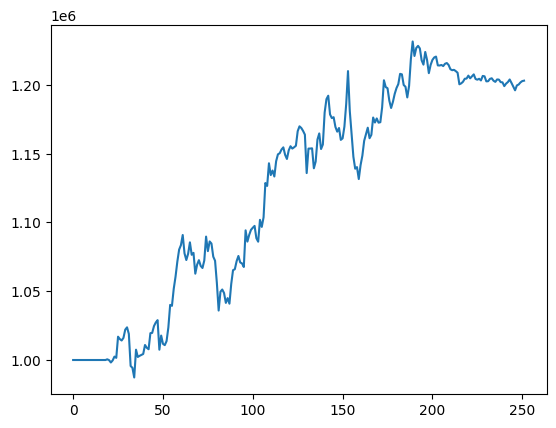

In [ ]:
%matplotlib inline
if df_account_value_mda.empty or "account_value" not in df_account_value_mda.columns or df_account_value_mda["account_value"].dropna().empty:
    print("No account value data available for plot; skipping.")
else:
    df_account_value_mda.account_value.plot()


<a id='6.1'></a>
## 7.1 BackTestStats
pass in df_account_value, this information is stored in env class


In [ ]:
print("==============Get Backtest Results===========")
now = datetime.datetime.now().strftime('%Y%m%d-%Hh%M')

if mda_audit_result.mda_stats is None:
    print("mda_stats unavailable; skipping stats display.")
else:
    perf_stats_all = mda_audit_result.mda_stats.copy()
    display(perf_stats_all)

==============Get Backtest Results===========


,0
Annual return,0.203913
Cumulative returns,0.203026
Annual volatility,0.114506
Sharpe ratio,1.678257
Calmar ratio,3.144940
Stability,0.896831
Max drawdown,-0.064838
Omega ratio,1.375075
Sortino ratio,2.601652
Skew,0.002609


In [ ]:
print("==============Get Baseline Stats===========")
if mda_audit_result.baseline is None or mda_audit_result.baseline_stats is None:
    print("Baseline data unavailable; skipping baseline stats.")
else:
    df_dji_ = mda_audit_result.baseline.copy()
    stats = mda_audit_result.baseline_stats.copy()
    display(stats)

==============Get Baseline Stats===========


,0
Annual return,0.216780
Cumulative returns,0.215833
Annual volatility,0.153633
Sharpe ratio,1.353141
Calmar ratio,2.166638
Stability,0.772204
Max drawdown,-0.100054
Omega ratio,1.284542
Sortino ratio,2.314066
Skew,2.011085


In [ ]:
output_path = run_dir / "audit/results/tail_gae_stats.csv"
print("Tail_GAE stats :", output_path)

Tail_GAE stats : <results_root>/Tail_GAE/1321b_ctrl/seed_9/20261018_211323/audit/results/tail_gae_stats.csv


In [ ]:
if mda_audit_result.baseline is None:
    print("Baseline data unavailable; skipping DJI export.")
else:
    df_dji = mda_audit_result.baseline[["date", "dji"]].copy()
    print("df_dji: ", df_dji)
    df_dji = df_dji.set_index("date")
    print("df_dji: ", df_dji)
    df_dji.to_csv(run_dir / "audit/results/df_dji_indexed.csv")


df_dji:             date           dji
0    2025-04-04  1.000000e+06
1    2025-04-07  9.908845e+05
2    2025-04-08  9.825324e+05
3    2025-04-09  1.059862e+06
4    2025-04-10  1.033376e+06
..          ...           ...
247  2026-03-31  1.209492e+06
248  2026-04-01  1.215344e+06
249  2026-04-02  1.213750e+06
250  2026-04-06  1.218062e+06
251  2026-04-07  1.215833e+06

[252 rows x 2 columns]
df_dji:                       dji
date                    
2025-04-04  1.000000e+06
2025-04-07  9.908845e+05
2025-04-08  9.825324e+05
2025-04-09  1.059862e+06
2025-04-10  1.033376e+06
...                  ...
2026-03-31  1.209492e+06
2026-04-01  1.215344e+06
2026-04-02  1.213750e+06
2026-04-06  1.218062e+06
2026-04-07  1.215833e+06

[252 rows x 1 columns]


<a id='6.2'></a>
## 7.2 BackTestPlot


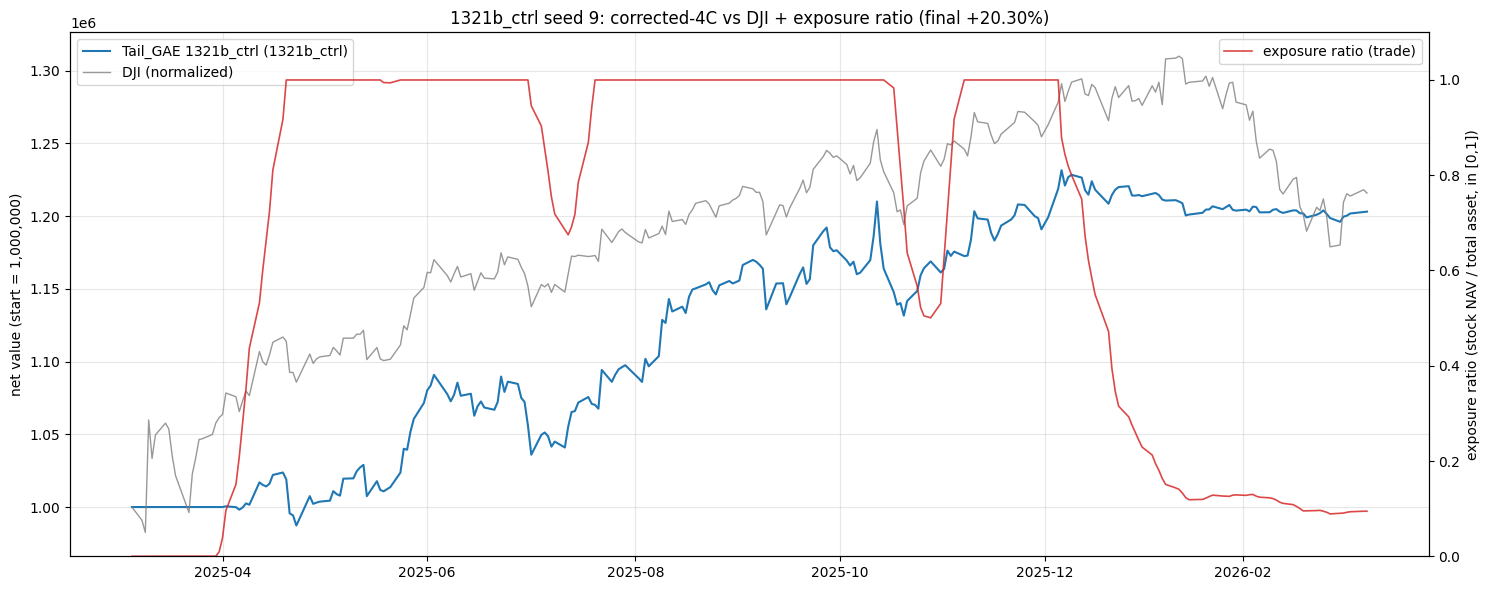

In [ ]:
# 1321b_ctrl Phase 9 1321b_ctrl: corrected-4C + 301-dim policy + 1200 normalization.
import glob

account_file = sorted(glob.glob(str(run_dir / "audit" / "results" / "df_account_value_*.csv")))[0]
acct = pd.read_csv(account_file, parse_dates=["date"]).set_index("date")["account_value"]
dji = pd.read_csv(run_dir / "audit" / "results" / "df_dji.csv", parse_dates=["date"])
dji = dji.set_index("date")["dji"]

exposure_parts = []
for window_label in ("iter_126", "iter_189", "iter_252", "iter_315"):
    trade_file = run_dir / "tail_mechanism" / "trade" / f"{window_label}.csv"
    trade = pd.read_csv(trade_file, parse_dates=["date"])
    exposure_parts.append(trade[["date", "gross_exposure"]])
exposure = (
    pd.concat(exposure_parts)
    .drop_duplicates("date")
    .sort_values("date")
    .set_index("date")["gross_exposure"]
)

acct_plot, exposure_plot = acct.align(exposure, join="inner")
dji_plot = dji.reindex(acct_plot.index)
final_return = acct_plot.iloc[-1] / acct_plot.iloc[0] - 1.0

fig, ax1 = plt.subplots(figsize=(15, 6))
ax1.plot(acct_plot.index, acct_plot.values, label="Tail_GAE 1321b_ctrl (1321b_ctrl)", linewidth=1.5, color="tab:blue")
ax1.plot(dji_plot.index, dji_plot.values, label="DJI (normalized)", linewidth=1.0, alpha=0.8, color="tab:gray")
ax1.set_ylabel("net value (start = 1,000,000)")
ax1.set_title(f"1321b_ctrl seed {seed}: corrected-4C vs DJI + exposure ratio (final {final_return:+.2%})")
ax1.legend(loc="upper left")
ax1.grid(alpha=0.3)

ax2 = ax1.twinx()
ax2.plot(exposure_plot.index, exposure_plot.values, label="exposure ratio (trade)", linewidth=1.2, color="tab:red", alpha=0.85)
ax2.set_ylabel("exposure ratio (stock NAV / total asset, in [0,1])")
ax2.set_ylim(0, 1.1)
ax2.legend(loc="upper right")
plt.tight_layout()
plt.show()
